In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Дата          301355 non-null  datetime64[ns]
 1   Склад         301355 non-null  int64         
 2   Контрагент    301355 non-null  object        
 3   Номенклатура  301355 non-null  object        
 4   Количество    301355 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.5+ MB


Сразу переведем столбец "Дата" в правильный формат

In [5]:
df['Дата'] = pd.to_datetime(df['Дата'])

Сгруппируйте данные по дате, посчитайте количество продаж

In [14]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество_продаж')

Вывести несколько первых строк сгруппированных данных

In [15]:
grouped_df.head()

,Дата,Количество_продаж
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719


In [89]:
grouped_df

,Дата,Количество_продаж
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719
...,...,...
200,2018-08-26,1462
201,2018-08-28,1731
202,2018-08-29,1497
203,2018-08-30,1445


Нарисуйте график продаж у `grouped_df`

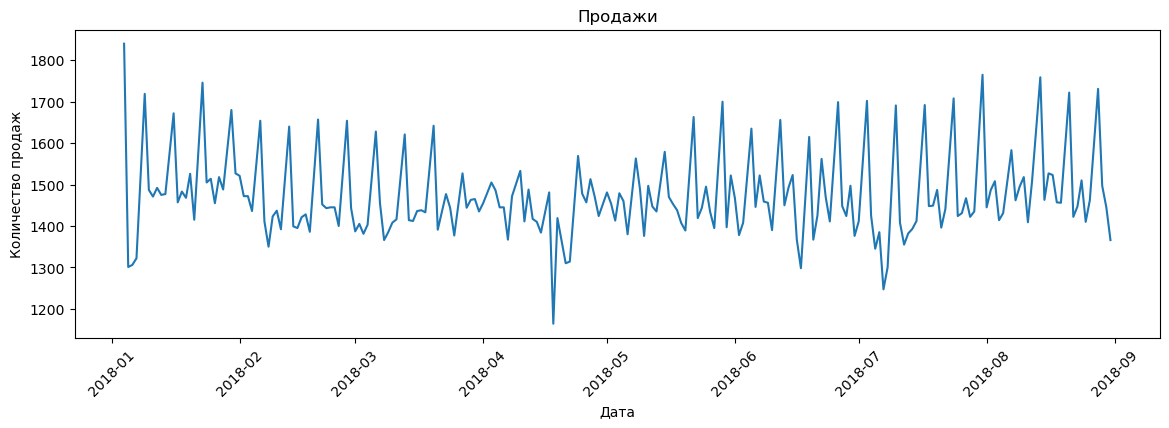

In [125]:
plt.figure(figsize=(14,4))
plt.plot(grouped_df['Дата'], grouped_df['Количество_продаж'])
plt.title('Продажи')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')

plt.xticks(rotation=45)

plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

При взгляде на данный график можно отметить, что продажи характеризуются высокой изменчивостью и не остаются на одном уровне. Линия графика сильно изрезана, поскольку каждое значение соответствует отдельному дню, и колебания происходят постоянно. Если рассматривать график не по отдельным точкам, а в целом, становится заметен выраженный недельный ритм. Волны повторяются, образуя последовательные подъёмы и спады. Пиковые значения обычно находятся в диапазоне от 1600 до 1700, иногда достигая 1750 или 1800. Впадины между пиками опускаются до 1400 или 1450, а в отдельных случаях и ниже 1300. Такой ритм, вероятно, связан с днями недели, когда покупательская активность может быть выше или ниже. При этом общий тренд отсутствует: продажи не демонстрируют устойчивого роста или падения и колеблются вокруг некоторого среднего уровня. Кроме того, на графике присутствуют отдельные выбросы, то есть дни с резким увеличением или снижением продаж по сравнению с соседними значениями. Это может объясняться распродажами, праздниками или крупными разовыми заказами. В целом график отражает стабильный, но неравномерный характер продаж, при котором сохраняется недельная цикличность и наблюдаются случайные всплески, однако отсутствует долгосрочная тенденция к росту или снижению.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [88]:
Q1 = df['Количество'].quantile(0.25)
Q3 = df['Количество'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

max_outlier = outliers_iqr.loc[outliers_iqr['Количество'].idxmax()]

print("Строка с максимальным выбросом:")
max_outlier.to_frame().T

Строка с максимальным выбросом:


,Дата,Склад,Контрагент,Номенклатура,Количество
218822,2018-06-28 00:00:00,1,address_208,product_0,200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [50]:
filtered = df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6, 7, 8])) &
    (df['Дата'].dt.dayofweek == 2)
]

top_products = (
    filtered.groupby('Номенклатура')['Количество']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

top1 = top_products.iloc[0]
print(f"Топовый товар: {top1['Номенклатура']} — суммарные продажи: {top1['Количество']}")

Топовый товар: product_1 — суммарные продажи: 2267


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [99]:
weather_raw = pd.read_csv(
    'Weather.csv',
    skiprows=6,
    sep=';',
    index_col= False
)

weather_raw.head()

,Местное время в Астане,T,Po,P,Pa,U,DD,Ff,ff10,ff3,...,Cm,Ch,VV,Td,RRR,tR,E,Tg,E',sss
0,01.09.2018 23:00,5.5,737.1,769.1,0.1,84.0,"Ветер, дующий с северо-северо-востока",2,NaN,NaN,...,NaN,NaN,NaN,2.9,Следы осадков,12.0,NaN,NaN,NaN,NaN
1,01.09.2018 20:00,6.1,737.0,769.0,1.0,78.0,"Ветер, дующий с севера",2,NaN,NaN,...,"Высококучевых, высокослоистых или слоисто-дожд...","Перистых, перисто-кучевых или перисто-слоистых...",NaN,2.5,Следы осадков,12.0,NaN,NaN,NaN,NaN
2,01.09.2018 17:00,7.5,736.0,767.7,0.2,78.0,"Ветер, дующий с северо-востока",1,NaN,NaN,...,"Высококучевых, высокослоистых или слоисто-дожд...","Перистых, перисто-кучевых или перисто-слоистых...",10.0,3.8,NaN,NaN,NaN,NaN,NaN,NaN
3,01.09.2018 14:00,9.1,735.8,767.4,-0.5,55.0,"Ветер, дующий с северо-северо-востока",3,NaN,NaN,...,"Высококучевых, высокослоистых или слоисто-дожд...","Перистых, перисто-кучевых или перисто-слоистых...",10.0,0.5,NaN,NaN,NaN,NaN,NaN,NaN
4,01.09.2018 11:00,7.7,736.3,768.1,-0.2,61.0,"Ветер, дующий с северо-северо-востока",3,NaN,NaN,...,NaN,NaN,10.0,0.5,Следы осадков,12.0,NaN,NaN,NaN,NaN


In [103]:
weather = weather_raw[['Местное время в Астане', 'T']].copy()
weather.columns = ['Дата_время', 'T']

weather['Дата_время'] = pd.to_datetime(weather['Дата_время'], dayfirst=True)

weather['Дата'] = weather['Дата_время'].dt.normalize()

daily_temp = (
    weather.groupby('Дата', as_index=False)['T']
    .mean()
    .rename(columns={'T': 'T_средняя'})
)

In [104]:
grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата'])
daily_temp['Дата'] = pd.to_datetime(daily_temp['Дата'])

merged = grouped_df.merge(daily_temp, on='Дата', how='left')
merged.head()

,Дата,Количество_продаж,T_средняя
0,2018-01-04,1840,-14.0750
1,2018-01-05,1301,-16.8625
2,2018-01-06,1306,-13.3000
3,2018-01-07,1322,-12.7500
4,2018-01-09,1719,-6.2500


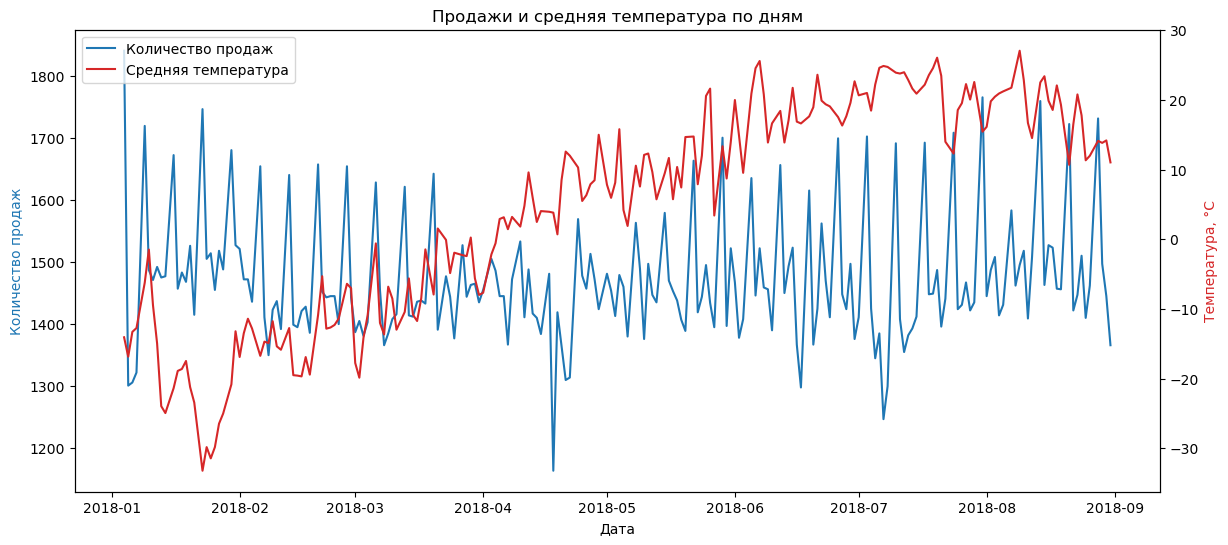

In [124]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(merged['Дата'], merged['Количество_продаж'], color='tab:blue', label='Количество продаж')
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(merged['Дата'], merged['T_средняя'], color='tab:red', label='Средняя температура')
ax2.set_ylabel('Температура, °C', color='tab:red')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Продажи и средняя температура по дням')
plt.show()

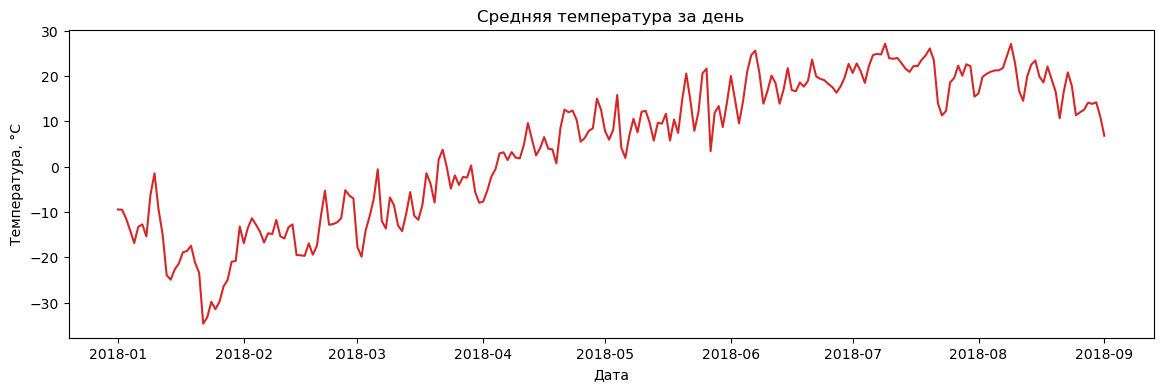

In [112]:
plt.figure(figsize=(14, 4))
plt.plot(daily_temp['Дата'], daily_temp['T_средняя'], color='tab:red')
plt.title('Средняя температура за день')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.show()